# Bicep curls replacement model experiment
Deployment target: timestamped acceleration in g and gyroscope in degrees/s from the new watch, not precomputed gravity or angles. A shared live processor produces 17 features after each completed repetition, followed by the new scaler and Isolation Forest. Compare **old-data-only** and **old plus new watch** training with separate scalers. Keep old labeled atypical data for validation/test according to participant splits; keep the named Mbient typical and atypical recordings as an external check only.

**Run All** creates a new versioned output folder, review plots, feature tables, held-out results, and a candidate model bundle. It never overwrites the deployed four-feature model. Use the project `ml/.venv` kernel (NumPy, SciPy, scikit-learn, Matplotlib); pandas is not needed.

This first run is explicitly exploratory. New-watch recordings are **assumed intended typical**, not reviewed ground truth. Their first wearing intervals were visually proposed; the second placements are excluded until reviewed. Mounting axes and old sensor-unit conversion assumptions remain unverified. The notebook will report these as blockers to deployment rather than claiming a validated replacement.

**Executed pilot result:** the pooled candidate flagged 9/9 usable repetitions from the held-out new-watch participant as atypical (their intended-typical labels are provisional). It is **not ready to replace the live model**. The participant-balanced fit used only 27 repetitions; review exclusions and segmentation before drawing conclusions. The first split lacked atypical validation/test examples, so this version uses a label-based class-coverage split. All results remain exploratory.


In [1]:
from pathlib import Path
from datetime import datetime,timezone
import csv,json,re,hashlib,sys,pickle,platform,warnings
import numpy as np
import matplotlib.pyplot as plt
from sklearn.preprocessing import StandardScaler
from sklearn.ensemble import IsolationForest
from sklearn.metrics import balanced_accuracy_score,roc_auc_score,confusion_matrix
import sklearn,scipy
REPO=Path('/Users/jadechng/Desktop/HomeStretch/HomeStretchRepo')
WATCH_DIR=Path('/Users/jadechng/Desktop/HomeStretch/recordings/1005')
OUTPUT=Path.cwd()/'bicep_v2_runs'/datetime.now(timezone.utc).strftime('%Y%m%dT%H%M%S%fZ');OUTPUT.mkdir(parents=True,exist_ok=False)
SEED=42
# First wearing periods only: session ID suffix -> movement window, seconds.
WATCH_WINDOWS={'1d1d07ea':(7,29),'1977cad0':(5,37),'efda0dcf':(5,44),
               '1ce3d7f5':(7,52),'15c80026':(7,37),'53c6c2fd':(6,36)}
# No future samples or full-session amplitude normalization in the 17-feature pipeline.
# Old Apple logger assumptions: user acceleration + gravity in g; gyro in rad/s.
# Negate total acceleration to match the specific-force convention of new/Mbient sensors.
# Verify these conventions and mounting frames before deployment.
REVIEW_STATUS={'watch_labels_confirmed':False,'movement_windows_confirmed':False,
              'sensor_units_and_axes_verified':False,'participant_identity_linkage_verified':False,
              'segmentation_review_passed':False,'live_app_parity_verified':False,
              'deployment_acceptance_criteria_predeclared':False}
print('Outputs:',OUTPUT)

Outputs: /Users/jadechng/Documents/ChatGPT/HomeStretch/bicep_v2_runs/20261017T160722289681Z


## 1 Inventory and split before fitting
Use the old **trimmed** files once; exclude repeatedly trimmed variants rather than treating them as independent sessions. Group both arms and both labels by old participant ID. Group new recordings by participant name. Seeded participant splits are created separately within each source: one old participant with atypical examples in validation and a different such participant in test, with remaining old participants in training; 2/1/1 participants for the new watch. Class coverage is selected using labels, never model scores.

These are dataset-local identity groups. If the same person appears under different identifiers across sources, fill in a cross-source identity map before claiming participant independence. The two named Mbient recordings have no verified participant IDs here; they remain an external recording-level check, never training or threshold-selection data. Timestamp-named Mbient files are not added as extra labeled examples.

In [2]:
def readcsv(p):
    with Path(p).open(newline='') as f:return list(csv.DictReader(f))
def digest(p):return hashlib.sha256(Path(p).read_bytes()).hexdigest()
manifest=[];seen={};duplicates=[]
for label,folder in [(0,'Typical'),(1,'Atypical')]:
    for p in sorted((REPO/'Data/Trimmed'/folder).glob('*.csv')):
        if p.name.startswith('Trimmed_Trimmed_'):duplicates.append({'file':str(p),'reason':'repeatedly trimmed variant excluded'});continue
        match=re.search(r'(\d{3})_BicepCurl_([LR])_',p.name,re.I)
        if not match:continue
        h=digest(p)
        if h in seen:duplicates.append({'file':str(p),'reason':'exact duplicate','duplicate_of':seen[h]});continue
        seen[h]=str(p)
        manifest.append(dict(source='old',file=str(p),gyro_file=None,label=label,label_status='folder label',participant='old:'+match[1],side=match[2],sha256=h,window=None))
for p in sorted(WATCH_DIR.glob('*.csv')):
    m=json.loads(p.with_suffix('.json').read_text());h=m.get('homestretch',{})
    if h.get('exercise_id')!='bicep_curl':continue
    key=p.stem.rsplit('_',1)[-1]
    manifest.append(dict(source='watch',file=str(p),gyro_file=None,label=0,label_status='ASSUMED typical; unreviewed',participant='watch:'+h.get('patient_id','unknown').strip().lower(),side=h.get('side'),sha256=digest(p),window=WATCH_WINDOWS.get(key)))
for prefix,label in [('Typical',0),('left_atypical',1)]:
    a=REPO/'mbientcode/mbientdata'/f'{prefix}_Accelerometer.csv';g=a.with_name(f'{prefix}_Gyroscope.csv')
    if a.exists() and g.exists():manifest.append(dict(source='mbient',file=str(a),gyro_file=str(g),label=label,label_status='filename label; execution details unverified',participant='mbient:unknown',side='unknown',sha256=digest(a),gyro_sha256=digest(g),window=None))
rng=np.random.default_rng(SEED);split_map={}
for source in ['old','watch']:
    ids=sorted({r['participant'] for r in manifest if r['source']==source});ids=list(rng.permutation(ids))
    assert len(ids)>=4, f'Need at least four {source} participant groups.'
    ntest=max(1,len(ids)//5);nval=max(1,len(ids)//5)
    if source=='old':
        # Class-coverage constraint uses labels only, never features/scores.
        atypical_ids=[pid for pid in ids if any(r['participant']==pid and r['label']==1 for r in manifest)]
        assert len(atypical_ids)>=2,'Need distinct atypical participant groups for validation and test.'
        test_ids={atypical_ids[0]};val_ids={atypical_ids[1]}
        for pid in ids:split_map[pid]='test' if pid in test_ids else 'validation' if pid in val_ids else 'train'
    else:
        for i,pid in enumerate(ids):split_map[pid]='test' if i<ntest else 'validation' if i<ntest+nval else 'train'
for i,r in enumerate(manifest):r['session_id']=f'session_{i:03d}';r['split']='external' if r['source']=='mbient' else split_map[r['participant']]
(OUTPUT/'manifest.json').write_text(json.dumps(manifest,indent=2));(OUTPUT/'excluded_files.json').write_text(json.dumps(duplicates,indent=2))
print(json.dumps(split_map,indent=2))
for source in ['old','watch','mbient']:print(source,sum(r['source']==source for r in manifest),'files')

{
  "old:004": "train",
  "old:001": "train",
  "old:009": "train",
  "old:003": "test",
  "old:005": "train",
  "old:007": "validation",
  "old:002": "train",
  "old:006": "train",
  "old:011": "train",
  "watch:arshaan": "test",
  "watch:angel": "validation",
  "watch:anisha": "train",
  "watch:ashritha": "train"
}
old 20 files
watch 6 files
mbient 2 files


## 2 Shared processing that can be replayed live
All sources pass through the same six-axis orientation estimator at 50 Hz. Resampling uses the most recent available sample, never a future value. Gaps over 60 ms reset the state. Orientation is relative to the first valid pose of each block; this removes global starting pose, **not sensor mounting differences**. No fitted gyro-bias calibration is performed in this pilot.

A trailing five-sample smoother is causal. Segmentation uses rotation excursion from the initial pose with fixed 15-degree movement and 8-degree reversal rules; it does not choose a dominant axis from the full session. A trough is emitted only after a confirming rise, so feedback is delayed and the last repetition may remain unconfirmed. The output records that delay. This is an experimental segmenter, not the old offline `find_peaks` routine.

Features preserve the requested 17 definitions: duration, completion error, four features per angle, three correlations. Derivatives use timestamps within the completed repetition. They are available after the repetition closes, not instantaneously throughout it. Engineering exclusions are recorded; no completion-error gate is used to discard atypical return-to-start behavior. Constant-channel correlations are assigned zero.

In [3]:
"""Experimental causal bicep pipeline v2. Native mounting frames are not calibrated."""
import numpy as np
from scipy.spatial.transform import Rotation
from collections import deque
from itertools import combinations
FS=50.0
FEATURES=['duration_seconds','completion_error']+[f'{c}_{f}' for c in ['pitch','yaw','roll'] for f in ['rom','velocity_mean','peak_velocity','smoothness']]+[f'{a}_{b}_correlation' for a,b in combinations(['pitch','yaw','roll'],2)]

class OrientationStream:
    def __init__(self):
        self.r=None; self.r0=None; self.last=None; self.prev=None; self.unwrapped=None;self.history=deque(maxlen=5)
    def update(self,t,accel,gyro):
        if self.last is not None and t-self.last>.060001:self.__init__()
        if self.r is None:
            if not .5<np.linalg.norm(accel)<1.5:return None
            x,y,z=accel; self.r=Rotation.from_euler('xyz',[np.arctan2(y,z),np.arctan2(-x,np.hypot(y,z)),0]);self.r0=self.r
        else:
            dt=t-self.last; omega=np.deg2rad(gyro)
            norm=np.linalg.norm(accel)
            if .85<=norm<=1.15:omega+=.5*np.cross(accel/norm,self.r.inv().apply([0,0,1]))
            self.r=self.r*Rotation.from_rotvec(omega*dt)
        self.last=t
        relative=self.r0.inv()*self.r
        # Direct formulas avoid gimbal warnings; flag near-singularity separately.
        x,y,z,w=relative.as_quat()
        pitch=np.arcsin(np.clip(2*(w*y-z*x),-1,1))
        roll=np.arctan2(2*(w*x+y*z),1-2*(x*x+y*y))
        yaw=np.arctan2(2*(w*z+x*y),1-2*(y*y+z*z))
        e=np.rad2deg([pitch,yaw,roll]); singular=abs(np.cos(pitch))<.1
        if self.prev is None:self.unwrapped=e.copy()
        else:self.unwrapped+=(e-self.prev+180)%360-180
        self.prev=e.copy();self.history.append(self.unwrapped.copy())
        # Same fixed, trailing filter for every source; no future/session statistics.
        angles=np.mean(self.history,axis=0)
        excursion=np.rad2deg(relative.magnitude())
        return angles,excursion,singular

class RepStream:
    """Confirm each trough after a fixed 8-degree rise. Feedback occurs at emitted_at."""
    def __init__(self):self.mode='seek';self.low=None;self.high=None;self.start=None
    def update(self,i,value):
        if self.low is None:self.low=(i,value);return None
        if self.mode in ['seek','rise']:
            if value<self.low[1]:self.low=(i,value)
            if self.mode=='seek' and value-self.low[1]>=15:
                self.start=self.low[0];self.high=(i,value);self.mode='rise'
            elif self.mode=='rise':
                if self.high is None or value>self.high[1]:self.high=(i,value)
                if self.high[1]-value>=8:self.low=(i,value);self.mode='fall'
        else:
            if value<self.low[1]:self.low=(i,value)
            if value-self.low[1]>=8:
                result=(self.start,self.low[0],i)
                self.start=self.low[0];self.high=(i,value);self.mode='rise'
                return result
        return None

def features(t,a):
    a=a-np.mean(a[:5],axis=0);out={'duration_seconds':float(t[-1]-t[0]),'completion_error':float(np.sqrt(np.mean(np.mean(a[-5:,[0,2]],axis=0)**2)))}
    for j,c in enumerate(['pitch','yaw','roll']):
        v=np.gradient(a[:,j],t);acc=np.gradient(v,t);jerk=np.gradient(acc,t)
        out.update({f'{c}_rom':float(np.ptp(a[:,j])),f'{c}_velocity_mean':float(np.mean(abs(v))),f'{c}_peak_velocity':float(np.max(abs(v))),f'{c}_smoothness':float(-np.log1p(np.sqrt(np.mean(jerk**2))))})
    for j,k in combinations(range(3),2):out[f'{["pitch","yaw","roll"][j]}_{["pitch","yaw","roll"][k]}_correlation']=float(np.corrcoef(a[:,j],a[:,k])[0,1]) if min(np.std(a[:,j]),np.std(a[:,k]))>1e-8 else 0.
    return out

def align_streams(accel,gyro):
    # Inputs N x 4: seconds,x,y,z. Previous-observation hold never reads a future sample.
    a=accel[np.isfinite(accel).all(axis=1)];g=gyro[np.isfinite(gyro).all(axis=1)]
    if min(len(a),len(g))<5:return np.empty((0,8))
    if not (np.all(np.diff(a[:,0])>0) and np.all(np.diff(g[:,0])>0)):raise ValueError('Nonmonotonic timestamps')
    t=np.arange(max(a[0,0],g[0,0]),min(a[-1,0],g[-1,0])+1e-8,1/FS)
    ai=np.searchsorted(a[:,0],t,side='right')-1;gi=np.searchsorted(g[:,0],t,side='right')-1
    age=np.maximum(t-a[ai,0],t-g[gi,0]);good=age<=.060001
    return np.column_stack([t[good],a[ai[good],1:],g[gi[good],1:],age[good]])

def process(accel,gyro,window):
    joined=align_streams(accel,gyro);state=OrientationStream();detector=RepStream();trace=[];accepted=[];rejected=[];block=0;last=None;history=deque(maxlen=5)
    for row in joined:
        t=row[0]
        if last is not None and t-last>.060001:detector=RepStream();history.clear();block+=1
        last=t
        value=state.update(t,row[1:4],row[4:7])
        if value is None:continue
        angles,excursion,singular=value;history.append(excursion);excursion=float(np.mean(history))
        index=len(trace);trace.append([t,*angles,excursion,row[7],float(singular),block])
        if t<window[0] or t>window[1]:detector=RepStream();continue
        result=detector.update(index,excursion)
        if result is None:continue
        start,end,emit=result;rep=np.array(trace[start:end+1]);duration=rep[-1,0]-rep[0,0]
        reasons=[]
        if not .6<=duration<=8:reasons.append('duration outside engineering bounds')
        if np.ptp(rep[:,4])<15:reasons.append('excursion below 15 degrees')
        if np.any(rep[:,6]):reasons.append('Euler near singularity')
        if np.any(np.abs(np.diff(rep[:,1:4],axis=0))>90):reasons.append('angle jump')
        if np.mean(rep[:,5]>.04)>.1:reasons.append('excess stale sensor samples')
        record={'start_sec':float(rep[0,0]),'end_sec':float(rep[-1,0]),'emitted_at_sec':float(t),'feedback_delay_sec':float(t-rep[-1,0]),'block':block,'held_sample_fraction':float(np.mean(rep[:,5]>.002))}
        if reasons:rejected.append(dict(record,reason='; '.join(reasons)))
        else:accepted.append(dict(record,**features(rep[:,0],rep[:,1:4])))
    return accepted,rejected,np.asarray(trace)

In [4]:
def load_streams(r):
    data=readcsv(r['file']);source=r['source']
    if source=='old':
        t=np.array([float(x['seconds_elapsed']) for x in data]);t-=t[0]
        gravity=np.array([[float(x['gravity'+c]) for c in 'XYZ'] for x in data])
        user=np.array([[float(x['acceleration'+c]) for c in 'XYZ'] for x in data])
        gyro=np.rad2deg([[float(x['rotationRate'+c]) for c in 'XYZ'] for x in data])
        return np.column_stack([t,-(gravity+user)]),np.column_stack([t,gyro])
    if source=='watch':
        # Use the project's protocol reader to validate IDs, timestamps, sequence and validity.
        sys.path.insert(0,str(REPO/'signal-processing'))
        from session_pipeline.reader import load_recording
        rec=load_recording(r['file']);streams=rec['streams']
        return tuple(streams[k][streams[k][:,4]>0,:4] for k in ['acceleration','gyroscope'])
    def mb(p):
        rows=readcsv(p);keys=list(rows[0])
        return np.array([[float(x[keys[0]])/1000,*[float(x[k]) for k in keys[3:6]]] for x in rows])
    a,g=mb(r['file']),mb(r['gyro_file']);origin=min(a[0,0],g[0,0]);a[:,0]-=origin;g[:,0]-=origin
    return a,g # actual epoch timestamps, not separately zeroed elapsed columns

# Prefix invariance: appended samples must not alter already-emitted angles or reps.
t=np.arange(0,10,1/FS);theta=.7*(1-np.cos(2*np.pi*t/2))
a=np.column_stack([t,np.zeros(len(t)),np.sin(theta),np.cos(theta)])
g=np.column_stack([t,np.rad2deg(.7*np.pi*np.sin(np.pi*t)),np.zeros((len(t),2))])
full=process(a,g,(0,10));prefix=process(a[:300],g[:300],(0,10))
assert np.allclose(full[2][:len(prefix[2])],prefix[2])
assert [r for r in full[0] if r['emitted_at_sec']<=t[299]]==prefix[0]
assert len(FEATURES)==17
print('Passed prefix invariance check for orientation, smoothing and emitted repetitions.')

Passed prefix invariance check for orientation, smoothing and emitted repetitions.


## 3 Extract and review repetitions
Plots shade accepted candidate intervals. Check for missed reps, merged reps, rest and handling before changing review flags. All new first wearing periods are plotted; no second wearing period is silently included. Exported exclusions and counts expose data-quality failures instead of labeling them atypical.

old train typical 149 atypical 23
old validation typical 28 atypical 15
old test typical 28 atypical 22
watch train typical 27 atypical 0
watch validation typical 19 atypical 0
watch test typical 9 atypical 0
mbient external typical 14 atypical 16
Errors: []


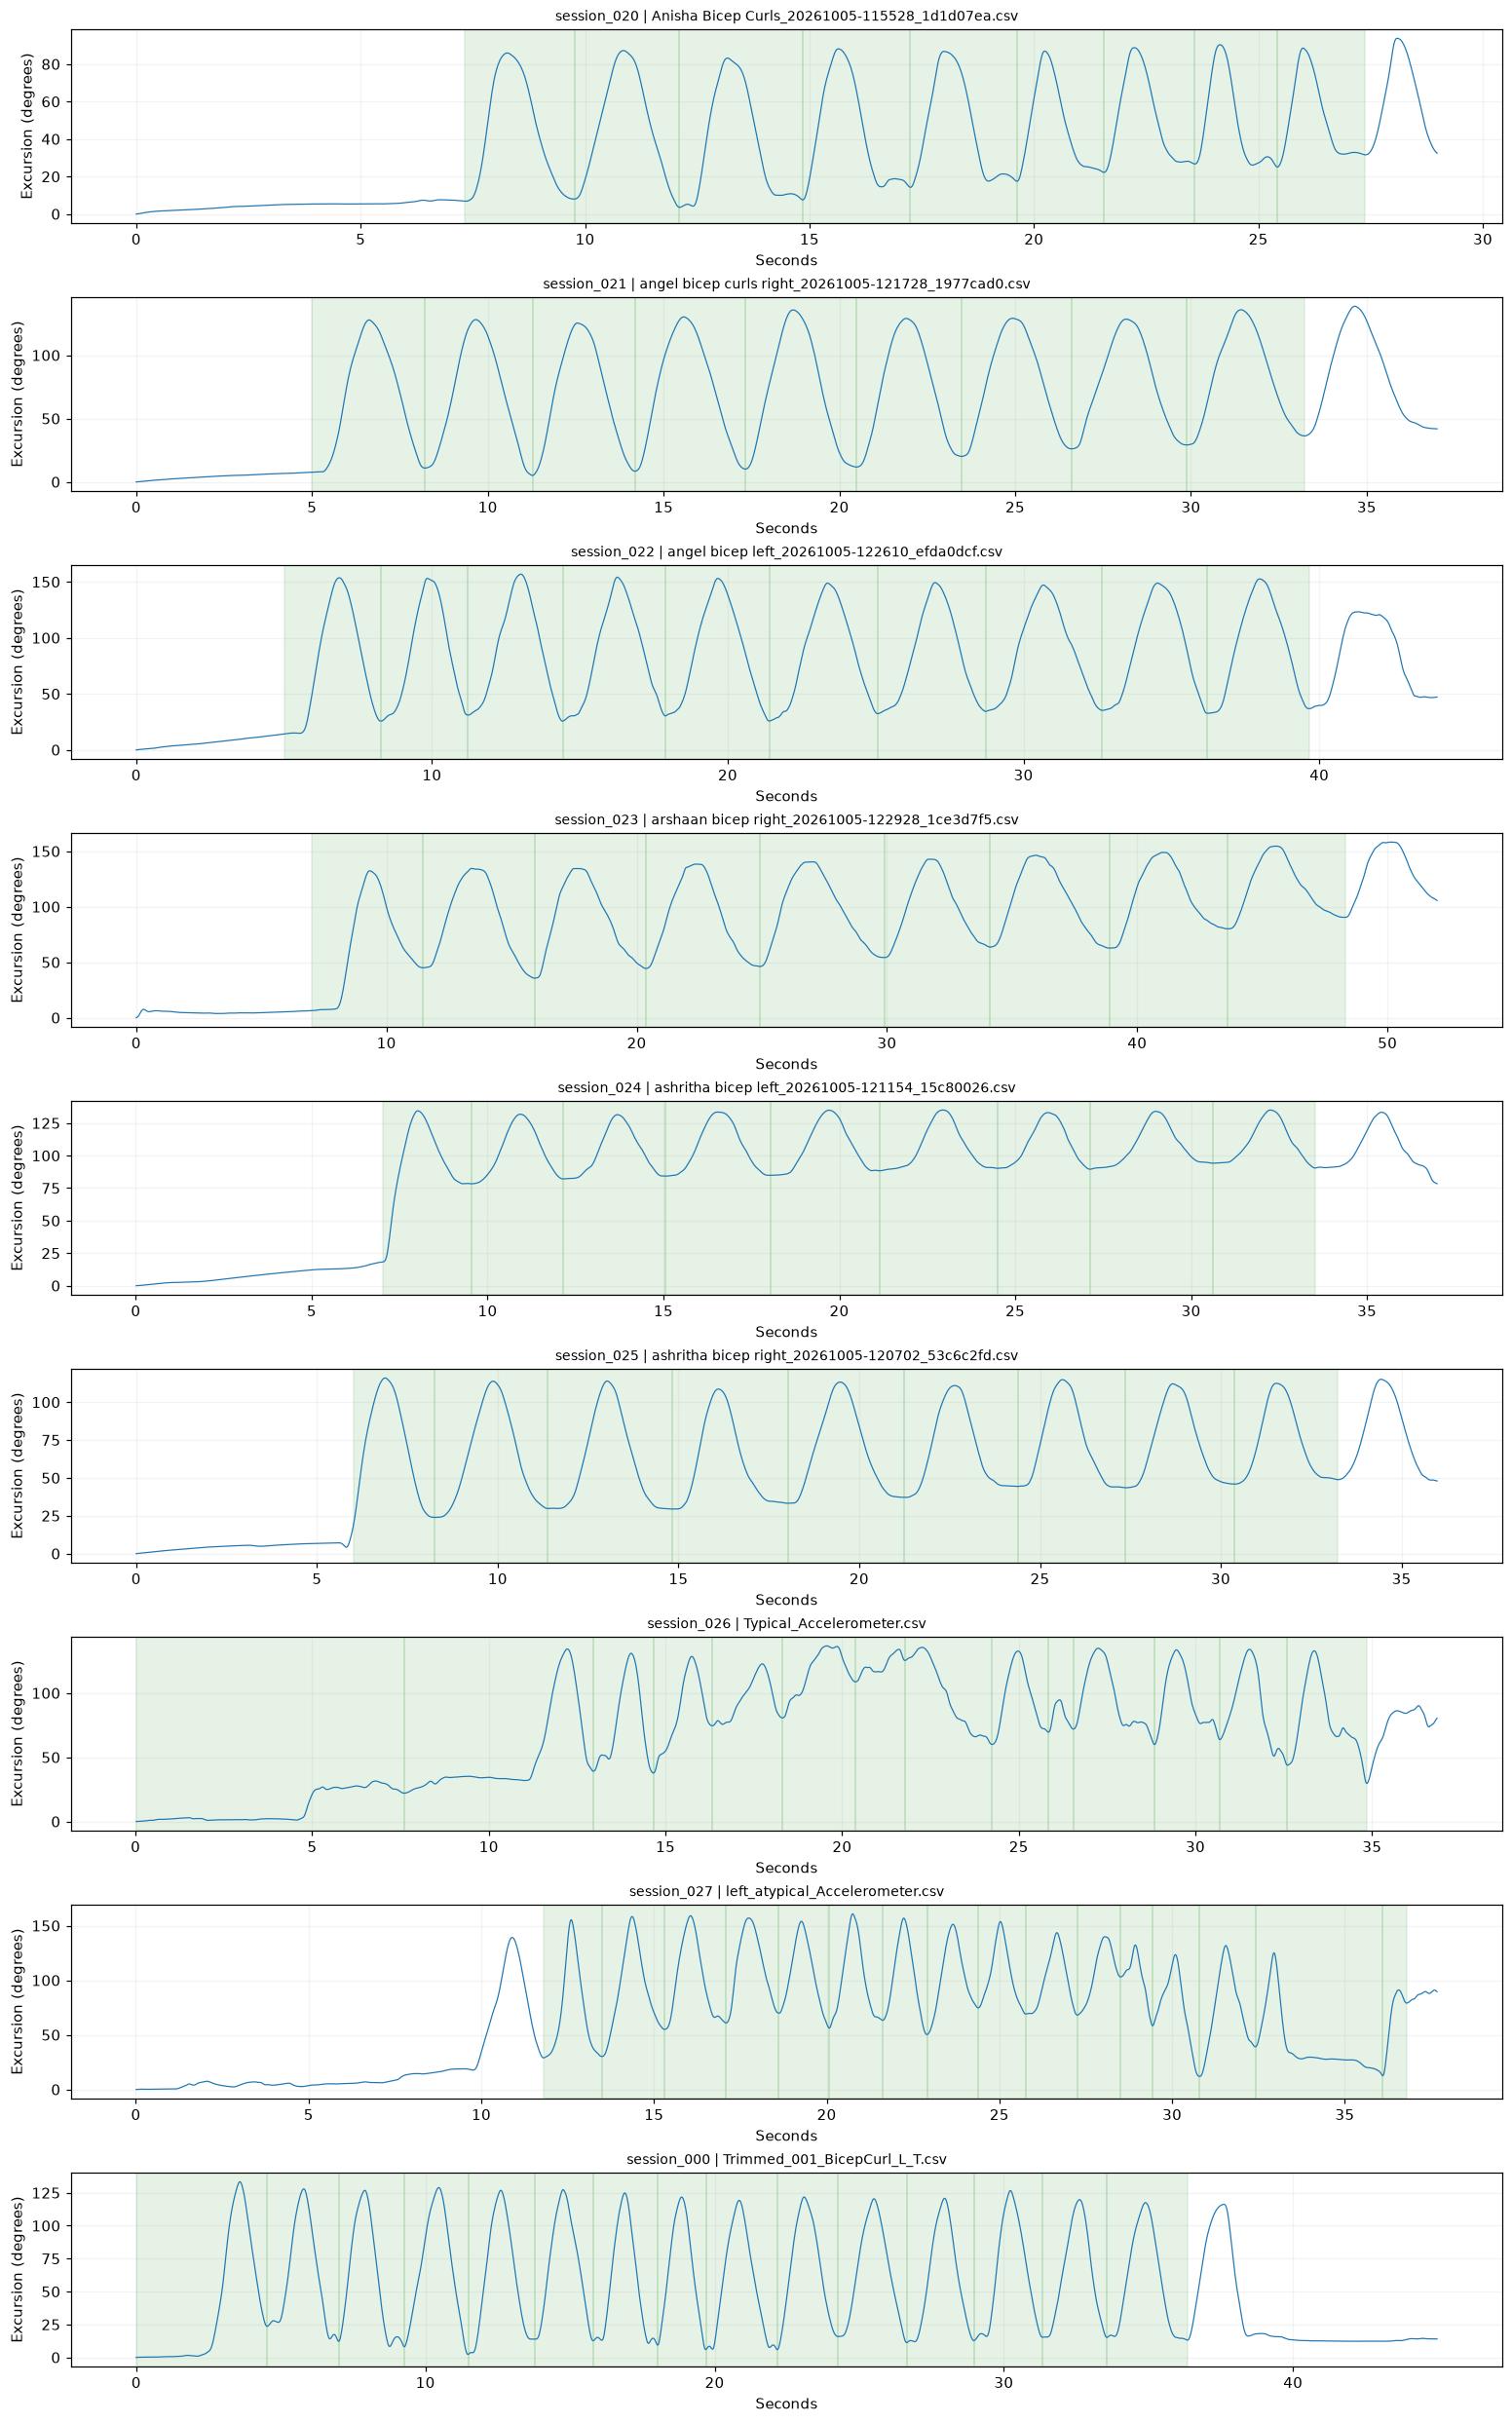

In [5]:
features_rows=[];rejections=[];session_audit=[];traces={}
for r in manifest:
    try:
        if r['source']=='watch' and r['window'] is None:raise ValueError('Missing movement window')
        a,g=load_streams(r)
        window=r['window'] or (max(a[0,0],g[0,0]),min(a[-1,0],g[-1,0]))
        # Exclude later handling from watch reconstruction; retain its initial pose.
        a=a[a[:,0]<=window[1]];g=g[g[:,0]<=window[1]]
        accepted,rejected,trace=process(a,g,window);traces[r['session_id']]=trace
        tags={k:r[k] for k in ['session_id','source','participant','side','label','label_status','split']}
        features_rows.extend(dict(tags,**x) for x in accepted)
        rejections.extend(dict(tags,**x) for x in rejected)
        session_audit.append(dict(tags,accepted=len(accepted),rejected=len(rejected),error=''))
    except (ValueError,KeyError,IndexError) as e:session_audit.append(dict(session_id=r['session_id'],source=r['source'],accepted=0,rejected=0,error=str(e)))
def save_table(name,rows):
    if not rows:return
    fields=list(dict.fromkeys(k for r in rows for k in r))
    with (OUTPUT/name).open('w',newline='') as f:w=csv.DictWriter(f,fieldnames=fields);w.writeheader();w.writerows(rows)
save_table('features.csv',features_rows);save_table('rejected_candidates.csv',rejections);save_table('session_audit.csv',session_audit)
for source in ['old','watch','mbient']:
    for split in ['train','validation','test','external']:
        group=[r for r in features_rows if r['source']==source and r['split']==split]
        if group:print(source,split,'typical',sum(r['label']==0 for r in group),'atypical',sum(r['label']==1 for r in group))
print('Errors:',[r for r in session_audit if r['error']])
selected=[r for r in manifest if r['source'] in ['watch','mbient']]+[next(r for r in manifest if r['source']=='old')]
fig,axes=plt.subplots(len(selected),1,figsize=(14,2.5*len(selected)),constrained_layout=True)
for ax,r in zip(axes,selected):
    trace=traces.get(r['session_id'],np.empty((0,8)))
    if len(trace):
        for b in np.unique(trace[:,-1]):
            z=trace[trace[:,-1]==b];ax.plot(z[:,0],z[:,4],lw=.8)
    for f in features_rows:
        if f['session_id']==r['session_id']:ax.axvspan(f['start_sec'],f['end_sec'],color='green',alpha=.1)
    ax.set_title(r['session_id']+' | '+Path(r['file']).name,fontsize=9);ax.set_ylabel('Excursion (degrees)');ax.set_xlabel('Seconds');ax.grid(alpha=.15)
fig.savefig(OUTPUT/'segmentation_review.png',dpi=110);plt.show()

## 4 Fit new scalers and forests using training typical data only
Two fresh 17-feature models are compared. No old model or scaler is reused. To stop a participant with more repetitions dominating the fit, sample the same number of training repetitions per participant. Hyperparameters are fixed before examining test results.

Thresholds use participant-weighted balanced accuracy on labeled validation data when both classes exist. If validation lacks either class, use the 95th percentile of typical validation scores and report that sensitivity was not calibrated. Test and Mbient external data never select thresholds. New-watch labels remain provisional even in validation and test.

In [6]:
X=np.array([[r[k] for k in FEATURES] for r in features_rows]);assert np.isfinite(X).all()
y=np.array([r['label'] for r in features_rows]);parts=np.array([r['split'] for r in features_rows]);sources=np.array([r['source'] for r in features_rows]);people=np.array([r['participant'] for r in features_rows])
assert all(not(set(people[parts==a])&set(people[parts==b])) for a,b in [('train','validation'),('train','test'),('validation','test')])
models={}
for name,allowed in [('old_only',['old']),('pooled',['old','watch'])]:
    train=np.flatnonzero((parts=='train')&(y==0)&np.isin(sources,allowed));ids=np.unique(people[train])
    assert len(ids)>=2,'Too few usable training participants.'
    count=min(sum(people[train]==p) for p in ids);rng=np.random.default_rng(SEED)
    train=np.concatenate([rng.choice(train[people[train]==p],count,replace=False) for p in ids])
    scaler=StandardScaler().fit(X[train]);forest=IsolationForest(n_estimators=300,contamination='auto',random_state=SEED,n_jobs=-1).fit(scaler.transform(X[train]))
    scores=-forest.decision_function(scaler.transform(X))
    val=np.flatnonzero((parts=='validation')&np.isin(sources,allowed))
    assert len(val)>0 and np.any(y[val]==0),'Need typical validation repetitions.'
    if len(np.unique(y[val]))==2:
        weights=np.array([1/sum(people[val]==p) for p in people[val]])
        thresholds=np.r_[scores[val].min()-1e-8,np.unique(scores[val]),scores[val].max()+1e-8]
        quality=[balanced_accuracy_score(y[val],scores[val]>th,sample_weight=weights) for th in thresholds]
        threshold=float(thresholds[int(np.argmax(quality))]);method='participant-weighted validation balanced accuracy'
    else:threshold=float(np.quantile(scores[val][y[val]==0],.95));method='typical validation 95th percentile; no sensitivity calibration'
    models[name]=dict(scaler=scaler,forest=forest,threshold=threshold,scores=scores,threshold_method=method,training_indices=train.tolist())
    print(name,'training reps:',len(train),'participants:',len(ids),'threshold:',threshold,'method:',method)

old_only training reps: 21 participants: 7 threshold: 0.011075460020831263 method: participant-weighted validation balanced accuracy
pooled training reps: 27 participants: 9 threshold: -0.0038782080380185824 method: participant-weighted validation balanced accuracy


## 5 Held-out evaluation and external Mbient check
Compare old-only and pooled models on the same held-out rows. Report false-positive rate on typical recordings, sensitivity on atypical recordings when available, and each participant separately. Missing classes produce missing metrics, not an invented accuracy score.

The small test sets and unreviewed new-watch labels make this a pilot. Mbient results are recording-level results with unknown participant linkage. If test results are used to revise the pipeline, this split is no longer a final untouched test.

[
  {
    "model": "old_only",
    "group": "old",
    "repetitions": 50,
    "participants": 1,
    "tn": 4,
    "fp": 24,
    "fn": 0,
    "tp": 22,
    "false_positive_rate": 0.8571428571428571,
    "sensitivity": 1.0,
    "auroc": 0.9301948051948052
  },
  {
    "model": "old_only",
    "group": "old/old:003",
    "repetitions": 50,
    "participants": 1,
    "tn": 4,
    "fp": 24,
    "fn": 0,
    "tp": 22,
    "false_positive_rate": 0.8571428571428571,
    "sensitivity": 1.0,
    "auroc": 0.9301948051948052
  },
  {
    "model": "old_only",
    "group": "watch",
    "repetitions": 9,
    "participants": 1,
    "tn": 0,
    "fp": 9,
    "fn": 0,
    "tp": 0,
    "false_positive_rate": 1.0,
    "sensitivity": null,
    "auroc": null
  },
  {
    "model": "old_only",
    "group": "watch/watch:arshaan",
    "repetitions": 9,
    "participants": 1,
    "tn": 0,
    "fp": 9,
    "fn": 0,
    "tp": 0,
    "false_positive_rate": 1.0,
    "sensitivity": null,
    "auroc": null
  },
  {
  

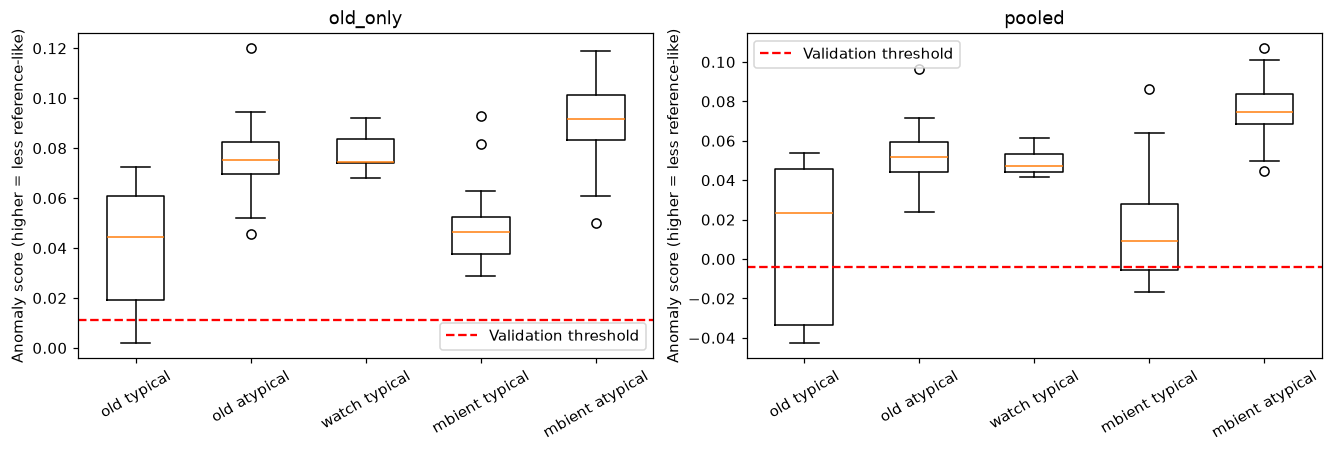

In [7]:
metrics=[]
def evaluate(name,mask,group):
    idx=np.flatnonzero(mask)
    if not len(idx):return
    m=models[name];truth=y[idx];pred=m['scores'][idx]>m['threshold'];tn,fp,fn,tp=confusion_matrix(truth,pred,labels=[0,1]).ravel()
    metrics.append(dict(model=name,group=group,repetitions=len(idx),participants=None if np.any(sources[idx]=='mbient') else len(set(people[idx])),tn=int(tn),fp=int(fp),fn=int(fn),tp=int(tp),false_positive_rate=float(fp/(tn+fp)) if tn+fp else None,sensitivity=float(tp/(tp+fn)) if tp+fn else None,auroc=float(roc_auc_score(truth,m['scores'][idx])) if len(set(truth))==2 else None))
for name in models:
    for source in ['old','watch','mbient']:
        mask=(sources==source)&np.isin(parts,['test','external']);evaluate(name,mask,source)
        for person in sorted(set(people[mask])):evaluate(name,mask&(people==person),source+'/'+person)
print(json.dumps(metrics,indent=2));save_table('evaluation.csv',metrics)
fig,axes=plt.subplots(1,2,figsize=(12,4),constrained_layout=True)
for ax,name in zip(axes,models):
    groups=[];labels=[]
    for source in ['old','watch','mbient']:
        for label in [0,1]:
            values=models[name]['scores'][(sources==source)&(y==label)&np.isin(parts,['test','external'])]
            if len(values):groups.append(values);labels.append(source+' '+('typical' if label==0 else 'atypical'))
    ax.boxplot(groups,tick_labels=labels);ax.axhline(models[name]['threshold'],color='red',ls='--',label='Validation threshold');ax.tick_params(axis='x',labelrotation=30);ax.set_title(name);ax.set_ylabel('Anomaly score (higher = less reference-like)');ax.legend()
plt.show()

## 6 Export the candidate and the replacement contract
Export the pooled scaler, forest, ordered features, preprocessing code and threshold together. They form one versioned bundle. Save both comparison models and metrics for review, but **do not choose deployment based on the test set alone**.

The deployed classifier currently expects four inputs. Replacing its pickle with this 17-input model would break that contract. A later app update must use this processing state, preserve state across incoming batches, calculate all 17 features in the exact order, apply this scaler and the saved anomaly-score threshold, and reproduce notebook outputs on recorded replay. The old model stays available for rollback.

`promotion_status.json` lists what remains unresolved. No checkbox alone authorizes deployment; numerical acceptance criteria must be declared and checked, and the live integration verified. The notebook never alters the active registry.

In [8]:
metadata={'schema_version':'bicep-causal17-pilot-v1','feature_order':FEATURES,'sampling_rate_hz':FS,
          'score_convention':'negative decision_function; atypical when score > threshold',
          'threshold':models['pooled']['threshold'],'threshold_method':models['pooled']['threshold_method'],
          'seed':SEED,'versions':{'python':platform.python_version(),'numpy':np.__version__,'scipy':scipy.__version__,'sklearn':sklearn.__version__},
          'input_contract':{'accelerometer':'timestamp seconds plus XYZ in g, sensor specific force','gyroscope':'same-clock timestamp seconds plus XYZ degrees/s','invalid_samples':'discard before resampling; gaps trigger resets','state':'preserve orientation, smoother and segmenter state across live callbacks','output':'17 ordered features only after a confirmed complete candidate'},'review_status':REVIEW_STATUS,'limitations':['Native mounting frames not anatomically aligned','New labels assumed typical','Old acceleration sign and gyro-unit assumptions unverified','Second watch placements excluded','Mbient participant identities unknown','No clinical accuracy claim'],
          'segmentation':{'excursion_trigger_deg':15,'reversal_deg':8,'minimum_duration_sec':.6,'maximum_duration_sec':8,'last_rep_may_be_unconfirmed':True},
          'fusion':{'gravity_gain_per_sec':.5,'gravity_gate_g':[.85,1.15],'gyro_bias_correction':False,'max_sample_age_sec':.06,'smoothing':'trailing mean 5 samples'},
          'replaces':'mbientcode/isolation_forest.pkl only after a separate tested app integration'}
for name,m in models.items():
    bundle=OUTPUT/name;bundle.mkdir()
    for key in ['scaler','forest']:
        with (bundle/(key+'.pkl')).open('wb') as f:pickle.dump(m[key],f)
    (bundle/'metadata.json').write_text(json.dumps(dict(metadata,threshold=m['threshold'],threshold_method=m['threshold_method']),indent=2))
# Verify saved pooled artifacts reproduce the scores on the same runtime.
with (OUTPUT/'pooled/forest.pkl').open('rb') as f:restored=pickle.load(f)
with (OUTPUT/'pooled/scaler.pkl').open('rb') as f:restored_scaler=pickle.load(f)
assert np.allclose(-restored.decision_function(restored_scaler.transform(X)),models['pooled']['scores'])
blockers=[k for k,v in REVIEW_STATUS.items() if not v]
status={'ready_to_replace':False,'status':'experimental candidate only','blockers':blockers,'active_model_changed':False}
(OUTPUT/'promotion_status.json').write_text(json.dumps(status,indent=2))
print('Exported:',OUTPUT/'pooled');print(json.dumps(status,indent=2))

Exported: /Users/jadechng/Documents/ChatGPT/HomeStretch/bicep_v2_runs/20261017T160722289681Z/pooled
{
  "ready_to_replace": false,
  "status": "experimental candidate only",
  "blockers": [
    "watch_labels_confirmed",
    "movement_windows_confirmed",
    "sensor_units_and_axes_verified",
    "participant_identity_linkage_verified",
    "segmentation_review_passed",
    "live_app_parity_verified",
    "deployment_acceptance_criteria_predeclared"
  ],
  "active_model_changed": false
}


In [9]:
(OUTPUT/'pooled'/'preprocessing.py').write_text('"""Experimental causal bicep pipeline v2. Native mounting frames are not calibrated."""\nimport numpy as np\nfrom scipy.spatial.transform import Rotation\nfrom collections import deque\nfrom itertools import combinations\nFS=50.0\nFEATURES=[\'duration_seconds\',\'completion_error\']+[f\'{c}_{f}\' for c in [\'pitch\',\'yaw\',\'roll\'] for f in [\'rom\',\'velocity_mean\',\'peak_velocity\',\'smoothness\']]+[f\'{a}_{b}_correlation\' for a,b in combinations([\'pitch\',\'yaw\',\'roll\'],2)]\n\nclass OrientationStream:\n    def __init__(self):\n        self.r=None; self.r0=None; self.last=None; self.prev=None; self.unwrapped=None;self.history=deque(maxlen=5)\n    def update(self,t,accel,gyro):\n        if self.last is not None and t-self.last>.060001:self.__init__()\n        if self.r is None:\n            if not .5<np.linalg.norm(accel)<1.5:return None\n            x,y,z=accel; self.r=Rotation.from_euler(\'xyz\',[np.arctan2(y,z),np.arctan2(-x,np.hypot(y,z)),0]);self.r0=self.r\n        else:\n            dt=t-self.last; omega=np.deg2rad(gyro)\n            norm=np.linalg.norm(accel)\n            if .85<=norm<=1.15:omega+=.5*np.cross(accel/norm,self.r.inv().apply([0,0,1]))\n            self.r=self.r*Rotation.from_rotvec(omega*dt)\n        self.last=t\n        relative=self.r0.inv()*self.r\n        # Direct formulas avoid gimbal warnings; flag near-singularity separately.\n        x,y,z,w=relative.as_quat()\n        pitch=np.arcsin(np.clip(2*(w*y-z*x),-1,1))\n        roll=np.arctan2(2*(w*x+y*z),1-2*(x*x+y*y))\n        yaw=np.arctan2(2*(w*z+x*y),1-2*(y*y+z*z))\n        e=np.rad2deg([pitch,yaw,roll]); singular=abs(np.cos(pitch))<.1\n        if self.prev is None:self.unwrapped=e.copy()\n        else:self.unwrapped+=(e-self.prev+180)%360-180\n        self.prev=e.copy();self.history.append(self.unwrapped.copy())\n        # Same fixed, trailing filter for every source; no future/session statistics.\n        angles=np.mean(self.history,axis=0)\n        excursion=np.rad2deg(relative.magnitude())\n        return angles,excursion,singular\n\nclass RepStream:\n    """Confirm each trough after a fixed 8-degree rise. Feedback occurs at emitted_at."""\n    def __init__(self):self.mode=\'seek\';self.low=None;self.high=None;self.start=None\n    def update(self,i,value):\n        if self.low is None:self.low=(i,value);return None\n        if self.mode in [\'seek\',\'rise\']:\n            if value<self.low[1]:self.low=(i,value)\n            if self.mode==\'seek\' and value-self.low[1]>=15:\n                self.start=self.low[0];self.high=(i,value);self.mode=\'rise\'\n            elif self.mode==\'rise\':\n                if self.high is None or value>self.high[1]:self.high=(i,value)\n                if self.high[1]-value>=8:self.low=(i,value);self.mode=\'fall\'\n        else:\n            if value<self.low[1]:self.low=(i,value)\n            if value-self.low[1]>=8:\n                result=(self.start,self.low[0],i)\n                self.start=self.low[0];self.high=(i,value);self.mode=\'rise\'\n                return result\n        return None\n\ndef features(t,a):\n    a=a-np.mean(a[:5],axis=0);out={\'duration_seconds\':float(t[-1]-t[0]),\'completion_error\':float(np.sqrt(np.mean(np.mean(a[-5:,[0,2]],axis=0)**2)))}\n    for j,c in enumerate([\'pitch\',\'yaw\',\'roll\']):\n        v=np.gradient(a[:,j],t);acc=np.gradient(v,t);jerk=np.gradient(acc,t)\n        out.update({f\'{c}_rom\':float(np.ptp(a[:,j])),f\'{c}_velocity_mean\':float(np.mean(abs(v))),f\'{c}_peak_velocity\':float(np.max(abs(v))),f\'{c}_smoothness\':float(-np.log1p(np.sqrt(np.mean(jerk**2))))})\n    for j,k in combinations(range(3),2):out[f\'{["pitch","yaw","roll"][j]}_{["pitch","yaw","roll"][k]}_correlation\']=float(np.corrcoef(a[:,j],a[:,k])[0,1]) if min(np.std(a[:,j]),np.std(a[:,k]))>1e-8 else 0.\n    return out\n\ndef align_streams(accel,gyro):\n    # Inputs N x 4: seconds,x,y,z. Previous-observation hold never reads a future sample.\n    a=accel[np.isfinite(accel).all(axis=1)];g=gyro[np.isfinite(gyro).all(axis=1)]\n    if min(len(a),len(g))<5:return np.empty((0,8))\n    if not (np.all(np.diff(a[:,0])>0) and np.all(np.diff(g[:,0])>0)):raise ValueError(\'Nonmonotonic timestamps\')\n    t=np.arange(max(a[0,0],g[0,0]),min(a[-1,0],g[-1,0])+1e-8,1/FS)\n    ai=np.searchsorted(a[:,0],t,side=\'right\')-1;gi=np.searchsorted(g[:,0],t,side=\'right\')-1\n    age=np.maximum(t-a[ai,0],t-g[gi,0]);good=age<=.060001\n    return np.column_stack([t[good],a[ai[good],1:],g[gi[good],1:],age[good]])\n\ndef process(accel,gyro,window):\n    joined=align_streams(accel,gyro);state=OrientationStream();detector=RepStream();trace=[];accepted=[];rejected=[];block=0;last=None;history=deque(maxlen=5)\n    for row in joined:\n        t=row[0]\n        if last is not None and t-last>.060001:detector=RepStream();history.clear();block+=1\n        last=t\n        value=state.update(t,row[1:4],row[4:7])\n        if value is None:continue\n        angles,excursion,singular=value;history.append(excursion);excursion=float(np.mean(history))\n        index=len(trace);trace.append([t,*angles,excursion,row[7],float(singular),block])\n        if t<window[0] or t>window[1]:detector=RepStream();continue\n        result=detector.update(index,excursion)\n        if result is None:continue\n        start,end,emit=result;rep=np.array(trace[start:end+1]);duration=rep[-1,0]-rep[0,0]\n        reasons=[]\n        if not .6<=duration<=8:reasons.append(\'duration outside engineering bounds\')\n        if np.ptp(rep[:,4])<15:reasons.append(\'excursion below 15 degrees\')\n        if np.any(rep[:,6]):reasons.append(\'Euler near singularity\')\n        if np.any(np.abs(np.diff(rep[:,1:4],axis=0))>90):reasons.append(\'angle jump\')\n        if np.mean(rep[:,5]>.04)>.1:reasons.append(\'excess stale sensor samples\')\n        record={\'start_sec\':float(rep[0,0]),\'end_sec\':float(rep[-1,0]),\'emitted_at_sec\':float(t),\'feedback_delay_sec\':float(t-rep[-1,0]),\'block\':block,\'held_sample_fraction\':float(np.mean(rep[:,5]>.002))}\n        if reasons:rejected.append(dict(record,reason=\'; \'.join(reasons)))\n        else:accepted.append(dict(record,**features(rep[:,0],rep[:,1:4])))\n    return accepted,rejected,np.asarray(trace)\n')
print('Saved exact replay preprocessing source with the candidate bundle.')

Saved exact replay preprocessing source with the candidate bundle.


### Explanation you can use
We trained a candidate bicep anomaly detector using features calculated from each completed repetition, removing the old dependence on the eventual session-average amplitude. We processed old and new recordings through a shared causal pipeline, fitted scalers and Isolation Forests on typical training participants, selected thresholds on validation data, and assessed separate test groups plus an external Mbient check. Device alignment, provisional labels and live-app parity remain explicit checks before replacing the deployed model.